In [1]:

 !pip install tensorflow --user

In [2]:
# ── Cell 1: Load and Prepare Iris Data ──
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.utils import to_categorical
import numpy as np

iris      = load_iris()
X         = iris.data
y         = iris.target

# Scale features — essential for neural networks
scaler    = StandardScaler()
X_scaled  = scaler.fit_transform(X)

# One-hot encode target (3 classes: setosa, versicolor, virginica)
y_encoded = to_categorical(y, num_classes=3)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_encoded, test_size=0.2, random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape: ", X_test.shape)
print("Classes    : Setosa, Versicolor, Virginica")


Train shape: (120, 4)
Test shape:  (30, 4)
Classes    : Setosa, Versicolor, Virginica


In [3]:
# ── Cell 2: Build and Train ANN ──
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential([
    Dense(10, activation='relu', input_shape=(4,)),
    Dense(8,  activation='relu'),
    Dense(3,  activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=8,
    validation_data=(X_test, y_test),
    verbose=1
)


C:\Users\i5 74h\AppData\Roaming\Python\Python311\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 10)                  │              50 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │              88 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 3)                   │              27 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 165 (660.00 B)

 Trainable params: 165 (660.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.4833 - loss: 0.9479 - val_accuracy: 0.4667 - val_loss: 0.8992
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6083 - loss: 0.8833 - val_accuracy: 0.5333 - val_loss: 0.8357
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6833 - loss: 0.8294 - val_accuracy: 0.8000 - val_loss: 0.7841
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.7167 - loss: 0.7842 - val_accuracy: 0.9000 - val_loss: 0.7399
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7833 - loss: 0.7455 - val_accuracy: 0.9000 - val_loss: 0.6982
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.8333 - loss: 0.7091 - val_accuracy: 0.9000 - val_loss: 0.6619
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8250 - loss: 0.6763 - val_accuracy: 0.9000 - val_loss: 0.6278
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8583 - loss: 0.6452 - val_accuracy: 0.9000 - v

In [4]:
# ── Cell 3: Evaluate Model ──
import matplotlib.pyplot as plt

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nFinal Test Accuracy : {test_acc:.4f}  ({test_acc*100:.2f}%)")
print(f"Final Test Loss     : {test_loss:.4f}")



Final Test Accuracy : 0.9667  (96.67%)
Final Test Loss     : 0.1106


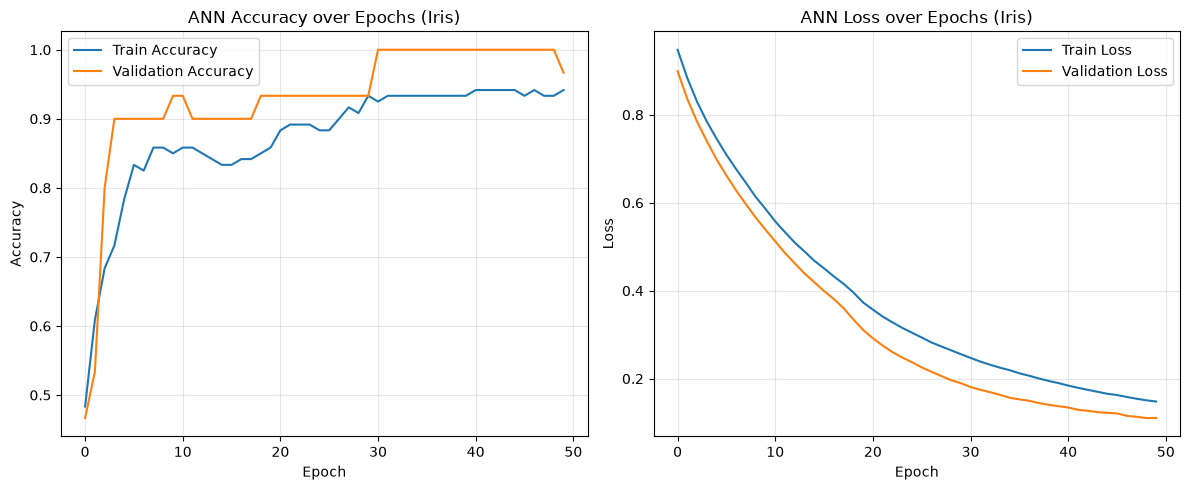

In [5]:
# ── Cell 4: Accuracy and Loss Plots ──
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'],     label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('ANN Accuracy over Epochs (Iris)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'],     label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('ANN Loss over Epochs (Iris)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [6]:
# ── Cell 5: Confusion Matrix and Classification Report ──
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

y_pred         = model.predict(X_test)
y_pred_classes = np.argmax(y_pred,  axis=1)
y_true_classes = np.argmax(y_test,  axis=1)

cm = confusion_matrix(y_true_classes, y_pred_classes)
print("Confusion Matrix:\n", cm)
print("\nClassification Report:")
print(classification_report(
    y_true_classes, y_pred_classes,
    target_names=['Setosa', 'Versicolor', 'Virginica']
))


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step
Confusion Matrix:
 [[10  0  0]
 [ 0  8  1]
 [ 0  0 11]]

Classification Report:
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       1.00      0.89      0.94         9
   Virginica       0.92      1.00      0.96        11

    accuracy                           0.97        30
   macro avg       0.97      0.96      0.97        30
weighted avg       0.97      0.97      0.97        30



In [7]:
# ── Cell 6: Predict a new sample ──
import numpy as np

# A sample flower measurement
new_flower = np.array([[5.1, 3.5, 1.4, 0.2]])
new_flower_scaled = scaler.transform(new_flower)

prediction = model.predict(new_flower_scaled)
class_names = ['Setosa', 'Versicolor', 'Virginica']
predicted   = class_names[np.argmax(prediction)]
confidence  = np.max(prediction) * 100

print(f"Input features : {new_flower[0]}")
print(f"Predicted class: {predicted}")
print(f"Confidence     : {confidence:.1f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step
Input features : [5.1 3.5 1.4 0.2]
Predicted class: Setosa
Confidence     : 99.9%
